# UMAMI Urban Heat — GPU-Native T_mrt Calculator

Custom GPU-vectorized mean radiant temperature calculator.
Replaces slow solweig-gpu (which uses CPU loops despite the name).

**Runtime:** A100 GPU
**Expected speed:** 2-10 seconds per patch (vs 15+ minutes with solweig-gpu)

## 1. Setup

In [1]:
import torch
print(f'PyTorch: {torch.__version__}')
print(f'CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    props = torch.cuda.get_device_properties(0)
    mem = getattr(props, 'total_memory', None) or getattr(props, 'total_mem', None)
    print(f'GPU Memory: {mem / 1e9:.1f} GB' if mem else 'GPU Memory: unknown')

PyTorch: 2.10.0+cu128
CUDA: True
GPU: NVIDIA A100-SXM4-40GB
GPU Memory: 42.4 GB


In [2]:
!pip install -q rasterio pyproj numpy

## 2. Mount Google Drive & Extract Data

In [3]:
import os, json
from google.colab import drive
drive.mount('/content/drive')

GDRIVE_ROOT = '/content/drive/MyDrive'
ARCHIVE_PATH = f'{GDRIVE_ROOT}/umami_patches.tar.gz'
LOCAL_DATA = '/content/urban_heat_data'
RESULTS_DIR = f'{GDRIVE_ROOT}/umami_solweig_results'

if os.path.exists(ARCHIVE_PATH):
    print(f'Found archive: {os.path.getsize(ARCHIVE_PATH)/1e6:.0f} MB')
else:
    print(f'ERROR: Upload umami_patches.tar.gz to Google Drive root first!')

os.makedirs(RESULTS_DIR, exist_ok=True)

Mounted at /content/drive
Found archive: 943 MB


In [4]:
import tarfile, time

if not os.path.exists(f'{LOCAL_DATA}/training/valid_patches.json'):
    print('Extracting patches to local disk...')
    t0 = time.time()
    with tarfile.open(ARCHIVE_PATH, 'r:gz') as tar:
        tar.extractall(LOCAL_DATA)
    print(f'Extracted in {time.time()-t0:.0f}s')
else:
    print('Patches already extracted')

with open(f'{LOCAL_DATA}/training/valid_patches.json') as f:
    valid_patches = json.load(f)['valid_patches']
print(f'Valid patches: {len(valid_patches)}')

PATCHES_DIR = f'{LOCAL_DATA}/training/patches'
MET_FILE = f'{LOCAL_DATA}/weather/mel_tullamarine_umep.txt'
print(f'Weather file exists: {os.path.exists(MET_FILE)}')

Extracting patches to local disk...


/tmp/ipython-input-2175511984.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(LOCAL_DATA)


Extracted in 15s
Valid patches: 987
Weather file exists: True


## 3. GPU-Native T_mrt Engine

All computation on GPU using vectorized tensor operations. No Python pixel loops.

In [5]:
import torch
import torch.nn.functional as F
import rasterio
import numpy as np
import math

device = torch.device('cuda')


def gpu_shadow_map(dsm_t, sun_alt_deg, sun_az_deg):
    """
    Vectorized shadow casting on GPU.
    For each pixel, march along the sun ray direction and check if
    any obstacle blocks the sun.
    """
    if sun_alt_deg <= 0:
        return torch.zeros_like(dsm_t)

    h, w = dsm_t.shape
    tan_alt = math.tan(math.radians(sun_alt_deg))
    az_rad = math.radians(sun_az_deg)

    # Direction TOWARD the sun in image coordinates:
    #   x (column) = east,  y (row) = south (top=north in raster)
    #   Sun azimuth from North clockwise: east=sin(az), north=cos(az)
    #   In image coords: east=+x, north=-y
    dx = math.sin(az_rad)       # east component toward sun
    dy = -math.cos(az_rad)      # north component (negated for image y-axis)

    shadow = torch.ones((h, w), device=device)  # 1=sunlit, 0=shadow

    # Max shadow length in pixels (height_range / tan_altitude)
    height_range = (dsm_t.max().item() - dsm_t.min().item())
    max_steps = min(int(height_range / max(tan_alt, 0.01)) + 2, max(h, w))
    max_steps = max(max_steps, 10)  # minimum 10 steps

    for step in range(1, max_steps + 1):
        # Sun ray height at 'step' meters distance from this pixel
        ray_h = dsm_t + tan_alt * step

        # Sample DSM at position 'step' pixels toward the sun
        offset_x = dx * step / (w - 1) * 2.0
        offset_y = dy * step / (h - 1) * 2.0

        theta = torch.tensor([[1, 0, offset_x],
                              [0, 1, offset_y]], dtype=torch.float32, device=device).unsqueeze(0)
        grid = F.affine_grid(theta, [1, 1, h, w], align_corners=True)

        src_h = F.grid_sample(
            dsm_t.unsqueeze(0).unsqueeze(0), grid,
            mode='bilinear', padding_mode='border', align_corners=True
        ).squeeze()

        # If obstacle toward the sun is taller than the sun ray, pixel is shadowed
        shadow[src_h > ray_h] = 0.0

    return shadow


def gpu_svf(dsm_t, n_directions=32, max_radius=100):
    """
    Approximate Sky View Factor using GPU ray marching.
    For each direction, find maximum elevation angle to horizon.
    SVF = mean(cos(max_elevation_angle)) across all directions.
    """
    h, w = dsm_t.shape
    svf_sum = torch.zeros((h, w), device=device)

    for i in range(n_directions):
        az = 360.0 * i / n_directions
        az_rad = math.radians(az)
        # Look outward in direction az (image coords: east=+x, south=+y)
        dx = math.sin(az_rad)
        dy = -math.cos(az_rad)

        max_angle = torch.zeros((h, w), device=device)

        for step in range(1, max_radius + 1):
            offset_x = dx * step / (w - 1) * 2.0
            offset_y = dy * step / (h - 1) * 2.0

            theta = torch.tensor([[1, 0, offset_x],
                                  [0, 1, offset_y]], dtype=torch.float32, device=device).unsqueeze(0)
            grid = F.affine_grid(theta, [1, 1, h, w], align_corners=True)

            src_h = F.grid_sample(
                dsm_t.unsqueeze(0).unsqueeze(0), grid,
                mode='bilinear', padding_mode='border', align_corners=True
            ).squeeze()

            elev = torch.atan2(src_h - dsm_t, torch.tensor(float(step), device=device))
            max_angle = torch.maximum(max_angle, elev)

        svf_sum += torch.cos(max_angle)

    return svf_sum / n_directions


def compute_solar_position(lat, lon, doy, hour, utc_offset=10):
    """
    Solar altitude and azimuth for given location, day of year, and hour.

    Args:
        lat, lon: location in degrees
        doy: day of year (1-366)
        hour: local standard time (AEST = UTC+10 for Melbourne, as in UMEP met files)
        utc_offset: timezone offset of the met file times (10 for AEST)

    Returns: (altitude_degrees, azimuth_degrees_from_north_clockwise)
    """
    # Convert local standard time to approximate solar time
    solar_hour = hour - utc_offset + lon / 15.0

    dec = -23.45 * math.cos(math.radians(360 / 365 * (doy + 10)))
    ha = 15 * (solar_hour - 12)
    lat_r, dec_r, ha_r = math.radians(lat), math.radians(dec), math.radians(ha)

    sin_alt = math.sin(lat_r) * math.sin(dec_r) + math.cos(lat_r) * math.cos(dec_r) * math.cos(ha_r)
    altitude = math.degrees(math.asin(max(-1, min(1, sin_alt))))

    if math.cos(math.radians(altitude)) < 0.001:
        return altitude, 180.0

    cos_az = (math.sin(dec_r) - math.sin(lat_r) * sin_alt) / (math.cos(lat_r) * math.cos(math.radians(altitude)))
    azimuth = math.degrees(math.acos(max(-1, min(1, cos_az))))
    if ha > 0:
        azimuth = 360 - azimuth

    return altitude, azimuth


def load_met_data(met_file):
    """Load UMEP meteorological file (space-separated, 24 columns, 1 header line)."""
    met = np.loadtxt(met_file, skiprows=1)
    return met


def get_met_row(met, doy, hour):
    """Get weather data row for specific DOY and hour."""
    mask = (met[:, 1].astype(int) == doy) & (met[:, 2].astype(int) == hour)
    if mask.any():
        return met[mask][0]
    # Fallback: nearest hour on same day
    day_mask = met[:, 1].astype(int) == doy
    if day_mask.any():
        day_data = met[day_mask]
        idx = np.argmin(np.abs(day_data[:, 2] - hour))
        return day_data[idx]
    raise ValueError(f'No weather data for DOY {doy} hour {hour}')


def gpu_compute_tmrt(patch_dir, met, doy, hour, svf_cache=None,
                     lat=-37.81, lon=144.96):
    """
    Compute mean radiant temperature for one patch at one hour.
    All heavy computation on GPU.

    Returns: (tmrt_numpy, rasterio_profile, svf_tensor_for_cache)
    """
    # Load rasters
    with rasterio.open(f'{patch_dir}/building_dsm.tif') as src:
        dsm = src.read(1).astype(np.float32)
        profile = src.profile.copy()
    with rasterio.open(f'{patch_dir}/dem.tif') as src:
        dem = src.read(1).astype(np.float32)
    with rasterio.open(f'{patch_dir}/trees.tif') as src:
        trees = src.read(1).astype(np.float32)
    with rasterio.open(f'{patch_dir}/albedo.tif') as src:
        albedo = src.read(1).astype(np.float32)

    # Handle nodata
    nodata_mask = (dsm < -9000) | (dem < -9000)
    dsm[nodata_mask] = 0
    dem[nodata_mask] = 0

    # Move to GPU
    dsm_t = torch.tensor(dsm, device=device)
    dem_t = torch.tensor(dem, device=device)
    trees_t = torch.tensor(trees, device=device)
    albedo_t = torch.tensor(albedo, device=device)

    # Effective DSM including trees
    dsm_eff = torch.maximum(dsm_t, dem_t + trees_t)

    # Weather data (UMEP column indices)
    row = get_met_row(met, doy, hour)
    Ta = float(row[11])       # air temperature C
    RH = float(row[10])       # relative humidity %
    kdown_g = float(row[14])  # global shortwave W/m2
    kdiff = float(row[21])    # diffuse shortwave W/m2
    ldown = float(row[16])    # longwave down W/m2
    wind = float(row[9])      # wind speed m/s

    # Solar position
    sun_alt, sun_az = compute_solar_position(lat, lon, doy, hour)

    SBC = 5.67e-8  # Stefan-Boltzmann constant
    nodata_t = torch.tensor(nodata_mask, device=device)

    if sun_alt <= 2:
        # Nighttime / very low sun — simplified: T_mrt ≈ Ta (no shortwave)
        tmrt = torch.full_like(dsm_t, Ta)
        svf_out = svf_cache
    else:
        # Shadow map (GPU vectorized)
        shadow = gpu_shadow_map(dsm_eff, sun_alt, sun_az)

        # SVF (GPU vectorized) — cache across temporal combos for same patch
        if svf_cache is not None:
            svf = svf_cache
        else:
            svf = gpu_svf(dsm_eff, n_directions=32, max_radius=100)
        svf_out = svf

        # Vegetation attenuation (trees transmit ~30% of radiation)
        veg_mask = (trees_t > 1.0).float()
        trans_veg = 0.3
        shadow_eff = shadow * (1.0 - veg_mask * (1.0 - trans_veg))

        # Direct beam radiation
        sin_alt = math.sin(math.radians(sun_alt))
        kdir = max(kdown_g - kdiff, 0.0)

        # Shortwave on horizontal surface
        Kdown = (kdir * shadow_eff * sin_alt +
                 kdiff * svf +
                 albedo_t * kdown_g * (1.0 - svf) * 0.5)

        # Shortwave reflected up
        Kup = albedo_t * Kdown

        # Longwave: sky emissivity from Brutsaert (1975)
        ea = 6.107 * 10 ** ((7.5 * Ta) / (237.3 + Ta)) * (RH / 100.0)
        w_ratio = 46.5 * ea / (Ta + 273.15)
        esky = 1.0 - (1.0 + w_ratio) * math.exp(-((1.2 + 3.0 * w_ratio) ** 0.5))
        esky = max(esky, 0.6)

        Ldown_sky = esky * SBC * (Ta + 273.15) ** 4
        Tsurf_wall = Ta + 2.0  # walls slightly warmer than air
        Ldown_wall = 0.97 * SBC * (Tsurf_wall + 273.15) ** 4
        Ld = svf * Ldown_sky + (1.0 - svf) * Ldown_wall

        # Longwave up from ground (sunlit ground warmer)
        Tground = Ta + 8.0 * shadow_eff
        Lu = 0.97 * SBC * (Tground + 273.15) ** 4

        # Absorbed radiation by a standing person (Fanger model)
        abs_sw = 0.7       # shortwave absorptivity of person
        eps_p = 0.97        # longwave emissivity of person
        fp = 0.06           # projected area factor for standing person

        # Shortwave absorbed (direct + diffuse + reflected)
        Kabs = abs_sw * fp * (Kdown + Kup + 4.0 * kdir * shadow_eff * max(math.cos(math.radians(sun_alt)), 0))

        # Longwave absorbed (from above and below)
        Labs = eps_p * (0.5 * Ld + 0.5 * Lu)

        # Total absorbed radiation → T_mrt
        Rabs = Kabs + Labs
        tmrt = (Rabs / (eps_p * SBC)).clamp(min=1.0) ** 0.25 - 273.15
        tmrt = tmrt.clamp(Ta - 15, 80.0)

    # Apply nodata mask
    tmrt[nodata_t] = -9999.0

    return tmrt.cpu().numpy(), profile, svf_out


print('GPU T_mrt engine loaded')
print(f'Device: {device} ({torch.cuda.get_device_name(0)})')

# Sanity check: solar position for Jan 15, 1pm Melbourne
alt, az = compute_solar_position(-37.81, 144.96, 15, 13)
print(f'Solar check — Jan 15, 13:00 AEST: altitude={alt:.1f}°, azimuth={az:.1f}°')
print(f'  (Expected: ~70° altitude, ~330° azimuth for Melbourne summer afternoon)')

GPU T_mrt engine loaded
Device: cuda (NVIDIA A100-SXM4-40GB)
Solar check — Jan 15, 13:00 AEST: altitude=71.4°, azimuth=329.7°
  (Expected: ~70° altitude, ~330° azimuth for Melbourne summer afternoon)


## 4. Single Patch Test

Test on one patch to verify GPU works and measure timing.

In [6]:
# Load weather data once
met = load_met_data(MET_FILE)
print(f'Weather data: {met.shape[0]} rows x {met.shape[1]} cols')

test_patch = valid_patches[len(valid_patches)//2]
test_dir = f'{PATCHES_DIR}/{test_patch}'
print(f'Test patch: {test_patch}')

# Show weather + solar conditions for the test
row = get_met_row(met, 15, 13)
sun_alt, sun_az = compute_solar_position(-37.81, 144.96, 15, 13)
print(f'\nWeather DOY=15 hour=13:')
print(f'  Ta={row[11]:.1f}°C, RH={row[10]:.0f}%, kdown={row[14]:.0f} W/m², kdiff={row[21]:.0f} W/m²')
print(f'  Sun altitude={sun_alt:.1f}°, azimuth={sun_az:.1f}°')

# Warm up GPU
_ = torch.zeros(1000, 1000, device=device)
torch.cuda.synchronize()

# Run test: Jan 15, 1pm (peak summer heat)
t0 = time.time()
tmrt, profile, svf_cached = gpu_compute_tmrt(test_dir, met, doy=15, hour=13)
torch.cuda.synchronize()
elapsed = time.time() - t0

valid = tmrt[(tmrt > -9000) & (tmrt < 80)]
print(f'\nDone in {elapsed:.2f}s')
print(f'T_mrt range: {valid.min():.1f} - {valid.max():.1f} °C')
print(f'T_mrt mean: {valid.mean():.1f} °C')
print(f'GPU memory: {torch.cuda.memory_allocated()/1e9:.2f} GB')
print(f'SVF cached: {svf_cached is not None}')

# Second run reusing SVF cache
t0 = time.time()
tmrt2, _, _ = gpu_compute_tmrt(test_dir, met, doy=15, hour=15, svf_cache=svf_cached)
torch.cuda.synchronize()
elapsed2 = time.time() - t0
valid2 = tmrt2[(tmrt2 > -9000) & (tmrt2 < 80)]
print(f'\nSecond temporal combo (cached SVF): {elapsed2:.2f}s')
print(f'T_mrt range: {valid2.min():.1f} - {valid2.max():.1f} °C')

Weather data: 8760 rows x 24 cols
Test patch: patch_0588

Weather DOY=15 hour=13:
  Ta=21.1°C, RH=43%, kdown=1034 W/m², kdiff=131 W/m²
  Sun altitude=71.4°, azimuth=329.7°

Done in 1.66s
T_mrt range: 13.0 - 37.4 °C
T_mrt mean: 32.3 °C
GPU memory: 0.01 GB
SVF cached: True

Second temporal combo (cached SVF): 0.03s
T_mrt range: 12.7 - 40.3 °C


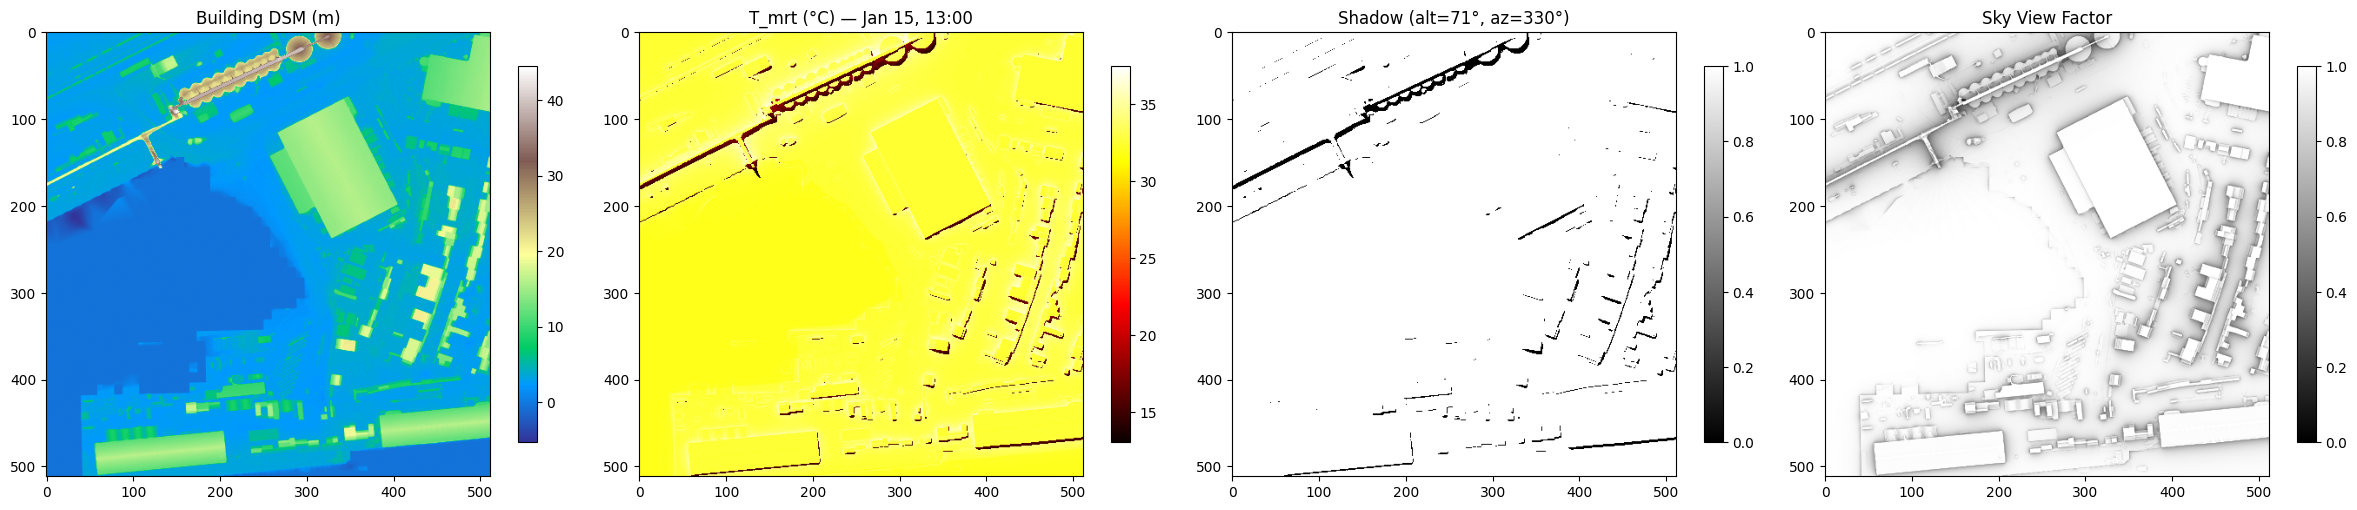

In [7]:
# Visualize the test result
import matplotlib.pyplot as plt

n_plots = 4 if svf_cached is not None else 3
fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 5))

# DSM
with rasterio.open(f'{test_dir}/building_dsm.tif') as src:
    dsm_vis = src.read(1)
dsm_plot = dsm_vis.copy().astype(float)
dsm_plot[dsm_plot < -9000] = np.nan
im0 = axes[0].imshow(dsm_plot, cmap='terrain')
axes[0].set_title('Building DSM (m)')
plt.colorbar(im0, ax=axes[0], shrink=0.8)

# T_mrt
tmrt_plot = tmrt.copy().astype(float)
tmrt_plot[tmrt_plot < -9000] = np.nan
im1 = axes[1].imshow(tmrt_plot, cmap='hot', vmin=np.nanmin(tmrt_plot), vmax=np.nanmax(tmrt_plot))
axes[1].set_title('T_mrt (°C) — Jan 15, 13:00')
plt.colorbar(im1, ax=axes[1], shrink=0.8)

# Shadow map (recompute quickly for visualization)
with rasterio.open(f'{test_dir}/building_dsm.tif') as s:
    dsm_raw = s.read(1).astype(np.float32)
with rasterio.open(f'{test_dir}/dem.tif') as s:
    dem_raw = s.read(1).astype(np.float32)
with rasterio.open(f'{test_dir}/trees.tif') as s:
    trees_raw = s.read(1).astype(np.float32)
dsm_raw[dsm_raw < -9000] = 0; dem_raw[dem_raw < -9000] = 0
dsm_eff_vis = np.maximum(dsm_raw, dem_raw + trees_raw)
dsm_eff_t = torch.tensor(dsm_eff_vis, device=device)
shadow_vis = gpu_shadow_map(dsm_eff_t, sun_alt, sun_az).cpu().numpy()
im2 = axes[2].imshow(shadow_vis, cmap='gray', vmin=0, vmax=1)
axes[2].set_title(f'Shadow (alt={sun_alt:.0f}°, az={sun_az:.0f}°)')
plt.colorbar(im2, ax=axes[2], shrink=0.8)

# SVF (if available)
if svf_cached is not None:
    svf_np = svf_cached.cpu().numpy()
    im3 = axes[3].imshow(svf_np, cmap='gray', vmin=0, vmax=1)
    axes[3].set_title('Sky View Factor')
    plt.colorbar(im3, ax=axes[3], shrink=0.8)

plt.tight_layout()
plt.show()

## 5. Batch Execution

Process all patches across temporal combinations.

In [8]:
# Temporal grid: 4 dates x hours
TEMPORAL_GRID = [
    (356, 9,  'd356_h09'),   # Dec 21, 9am
    (356, 11, 'd356_h11'),   # Dec 21, 11am
    (356, 13, 'd356_h13'),   # Dec 21, 1pm
    (356, 15, 'd356_h15'),   # Dec 21, 3pm
    (15,  9,  'd015_h09'),   # Jan 15, 9am
    (15,  11, 'd015_h11'),   # Jan 15, 11am
    (15,  13, 'd015_h13'),   # Jan 15, 1pm
    (15,  15, 'd015_h15'),   # Jan 15, 3pm
    (46,  9,  'd046_h09'),   # Feb 15, 9am
    (46,  13, 'd046_h13'),   # Feb 15, 1pm
    (306, 9,  'd306_h09'),   # Nov 1, 9am
    (306, 13, 'd306_h13'),   # Nov 1, 1pm
]

print(f'Patches: {len(valid_patches)}')
print(f'Temporal combos: {len(TEMPORAL_GRID)}')
print(f'Total runs: {len(valid_patches) * len(TEMPORAL_GRID)}')

Patches: 987
Temporal combos: 12
Total runs: 11844


In [9]:
# Progress tracking
PROGRESS_FILE = f'{LOCAL_DATA}/training/gpu_progress.json'

def load_progress():
    if os.path.exists(PROGRESS_FILE):
        with open(PROGRESS_FILE) as f:
            return json.load(f)
    return {'completed': {}, 'failed': {}, 'total_completed': 0, 'total_failed': 0}

def save_progress(progress):
    with open(PROGRESS_FILE, 'w') as f:
        json.dump(progress, f)

def is_done(progress, patch, label):
    return patch in progress.get('completed', {}) and label in progress['completed'][patch]

progress = load_progress()
print(f'Existing progress: {progress["total_completed"]} completed')

Existing progress: 0 completed


In [10]:
# Build job list
jobs = []
for patch_name in valid_patches:
    for doy, hour, label in TEMPORAL_GRID:
        if not is_done(progress, patch_name, label):
            jobs.append((patch_name, doy, hour, label))

print(f'Jobs to run: {len(jobs)}')
print(f'Already done: {len(valid_patches) * len(TEMPORAL_GRID) - len(jobs)}')

# Estimate
if len(jobs) > 0:
    first_run = elapsed   # from test above
    cached_run = elapsed2  # from cached SVF test
    # First temporal combo per patch needs SVF, rest are cached
    n_patches = len(valid_patches)
    n_temporal = len(TEMPORAL_GRID)
    est_hours = (n_patches * first_run + n_patches * (n_temporal - 1) * cached_run) / 3600
    print(f'\nEstimate: {est_hours:.1f} hours')
    print(f'  First run/patch: {first_run:.1f}s (includes SVF)')
    print(f'  Cached runs: {cached_run:.1f}s each')

Jobs to run: 11844
Already done: 0

Estimate: 0.5 hours
  First run/patch: 1.7s (includes SVF)
  Cached runs: 0.0s each


In [11]:
# ============ MAIN BATCH ============
import glob

batch_start = time.time()
completed = 0
failed = 0
total_jobs = len(jobs)
current_patch = None
svf_cache = None

for i, (patch_name, doy, hour, label) in enumerate(jobs):
    patch_dir = f'{PATCHES_DIR}/{patch_name}'

    # Reset SVF cache when switching patches
    if patch_name != current_patch:
        svf_cache = None
        current_patch = patch_name

    t0 = time.time()
    try:
        tmrt_result, profile, svf_cache = gpu_compute_tmrt(
            patch_dir, met, doy, hour, svf_cache=svf_cache
        )
        torch.cuda.synchronize()
        run_time = time.time() - t0

        # Save T_mrt as GeoTIFF
        out_dir = f'{patch_dir}/output_folder'
        os.makedirs(out_dir, exist_ok=True)
        out_path = f'{out_dir}/Tmrt_{label}.tif'
        profile.update(dtype='float32', count=1, compress='deflate')
        with rasterio.open(out_path, 'w', **profile) as dst:
            dst.write(tmrt_result.astype(np.float32), 1)

        completed += 1
        progress.setdefault('completed', {}).setdefault(patch_name, {})[label] = {
            'time_s': round(run_time, 2)
        }
        progress['total_completed'] = sum(len(v) for v in progress['completed'].values())

    except Exception as e:
        run_time = time.time() - t0
        failed += 1
        progress.setdefault('failed', {}).setdefault(patch_name, {})[label] = {
            'error': str(e)[:200]
        }
        progress['total_failed'] = sum(len(v) for v in progress.get('failed', {}).values())
        svf_cache = None  # Reset on failure

    done = completed + failed
    if done % 50 == 0 or done == total_jobs or done <= 5:
        elapsed_b = time.time() - batch_start
        rate = done / elapsed_b if elapsed_b > 0 else 0
        remaining = (total_jobs - done) / rate / 3600 if rate > 0 else 0
        print(f'[{done}/{total_jobs}] {completed} ok, {failed} fail | '
              f'{elapsed_b/60:.0f}m elapsed, ~{remaining:.1f}h left | '
              f'{patch_name}/{label} ({run_time:.1f}s)')
        save_progress(progress)

# Final
progress['batch_elapsed_s'] = round(time.time() - batch_start, 1)
save_progress(progress)
total_h = (time.time() - batch_start) / 3600
print(f'\n=== Batch complete ===')
print(f'Completed: {completed}, Failed: {failed}')
print(f'Total time: {total_h:.1f} hours')

[1/11844] 1 ok, 0 fail | 0m elapsed, ~2.7h left | patch_0007/d356_h09 (0.8s)
[2/11844] 2 ok, 0 fail | 0m elapsed, ~1.4h left | patch_0007/d356_h11 (0.0s)
[3/11844] 3 ok, 0 fail | 0m elapsed, ~0.9h left | patch_0007/d356_h13 (0.0s)
[4/11844] 4 ok, 0 fail | 0m elapsed, ~0.7h left | patch_0007/d356_h15 (0.0s)
[5/11844] 5 ok, 0 fail | 0m elapsed, ~0.6h left | patch_0007/d015_h09 (0.0s)
[50/11844] 50 ok, 0 fail | 0m elapsed, ~0.3h left | patch_0011/d356_h11 (0.0s)
[100/11844] 100 ok, 0 fail | 0m elapsed, ~0.5h left | patch_0015/d356_h15 (0.1s)
[150/11844] 150 ok, 0 fail | 0m elapsed, ~0.5h left | patch_0019/d015_h11 (0.1s)
[200/11844] 200 ok, 0 fail | 1m elapsed, ~0.6h left | patch_0023/d015_h15 (0.0s)
[250/11844] 250 ok, 0 fail | 1m elapsed, ~0.5h left | patch_0027/d046_h13 (0.0s)
[300/11844] 300 ok, 0 fail | 1m elapsed, ~0.5h left | patch_0031/d306_h13 (0.0s)
[350/11844] 350 ok, 0 fail | 1m elapsed, ~0.5h left | patch_0041/d356_h11 (0.0s)
[400/11844] 400 ok, 0 fail | 1m elapsed, ~0.4h lef

## 6. Intervention Mutations

In [12]:
import shutil

ALBEDO_ASPHALT = 0.12
ALBEDO_GRASS = 0.25
ALBEDO_ROOF_COOL = 0.70
ALBEDO_ROOF_STD = 0.15
LC_PAVED = 1
LC_BUILDINGS = 2
LC_VEGETATION = 4

def create_greening_mutation(src_dir, dst_dir, seed=42):
    os.makedirs(dst_dir, exist_ok=True)
    rng = np.random.RandomState(seed)
    for f in ['building_dsm.tif', 'dem.tif']:
        shutil.copy2(f'{src_dir}/{f}', f'{dst_dir}/{f}')
    with rasterio.open(f'{src_dir}/trees.tif') as s:
        trees = s.read(1); tp = s.profile.copy()
    with rasterio.open(f'{src_dir}/landcover.tif') as s:
        lc = s.read(1)
    plantable = ((lc == LC_PAVED) | (lc == 5)) & (trees < 1.0)
    coords = np.argwhere(plantable)
    if len(coords) > 0:
        for idx in rng.choice(len(coords), min(50, len(coords)), replace=False):
            cy, cx = coords[idx]
            h, r = rng.uniform(8, 15), rng.randint(3, 7)
            yy, xx = np.ogrid[max(0,cy-r):min(trees.shape[0],cy+r+1), max(0,cx-r):min(trees.shape[1],cx+r+1)]
            mask = (yy - cy)**2 + (xx - cx)**2 <= r**2
            trees[max(0,cy-r):min(trees.shape[0],cy+r+1), max(0,cx-r):min(trees.shape[1],cx+r+1)][mask] = \
                np.maximum(trees[max(0,cy-r):min(trees.shape[0],cy+r+1), max(0,cx-r):min(trees.shape[1],cx+r+1)][mask], h)
    with rasterio.open(f'{dst_dir}/trees.tif', 'w', **tp) as d:
        d.write(trees, 1)
    with rasterio.open(f'{src_dir}/albedo.tif') as s:
        albedo = s.read(1); ap = s.profile.copy()
    asphalt = np.abs(albedo - ALBEDO_ASPHALT) < 0.02
    ac = np.argwhere(asphalt)
    converted = np.zeros_like(asphalt)
    if len(ac) > 0:
        for idx in rng.choice(len(ac), int(len(ac)*0.3), replace=False):
            y, x = ac[idx]; albedo[y, x] = ALBEDO_GRASS; converted[y, x] = True
    with rasterio.open(f'{dst_dir}/albedo.tif', 'w', **ap) as d:
        d.write(albedo, 1)
    lc_new = lc.copy(); lc_new[converted] = LC_VEGETATION
    with rasterio.open(f'{src_dir}/landcover.tif') as s:
        lp = s.profile.copy()
    with rasterio.open(f'{dst_dir}/landcover.tif', 'w', **lp) as d:
        d.write(lc_new, 1)

def create_cool_roof_mutation(src_dir, dst_dir):
    os.makedirs(dst_dir, exist_ok=True)
    for f in ['building_dsm.tif', 'dem.tif', 'trees.tif', 'landcover.tif']:
        shutil.copy2(f'{src_dir}/{f}', f'{dst_dir}/{f}')
    with rasterio.open(f'{src_dir}/albedo.tif') as s:
        albedo = s.read(1); p = s.profile.copy()
    with rasterio.open(f'{src_dir}/landcover.tif') as s:
        lc = s.read(1)
    albedo[(lc == LC_BUILDINGS) & (np.abs(albedo - ALBEDO_ROOF_STD) < 0.03)] = ALBEDO_ROOF_COOL
    with rasterio.open(f'{dst_dir}/albedo.tif', 'w', **p) as d:
        d.write(albedo, 1)

print('Mutation functions ready')

Mutation functions ready


In [13]:
# Create + run mutations for first 100 patches
MUT_TEMPORAL = [(15, 13, 'd015_h13'), (356, 13, 'd356_h13')]
patches_to_mutate = valid_patches[:100]

print(f'Creating mutations for {len(patches_to_mutate)} patches...')
mut_jobs = []
for pn in patches_to_mutate:
    src = f'{PATCHES_DIR}/{pn}'
    for suffix, create_fn in [('_green', create_greening_mutation), ('_cool', create_cool_roof_mutation)]:
        mut_dir = f'{PATCHES_DIR}/{pn}{suffix}'
        if not os.path.exists(mut_dir):
            if suffix == '_green':
                create_fn(src, mut_dir, hash(pn) % (2**31))
            else:
                create_fn(src, mut_dir)
        for doy, hour, label in MUT_TEMPORAL:
            mut_name = f'{pn}{suffix}'
            if not is_done(progress, mut_name, label):
                mut_jobs.append((mut_name, mut_dir, doy, hour, label))

print(f'Mutation jobs: {len(mut_jobs)}')

mut_start = time.time()
mut_ok = mut_fail = 0
for i, (mut_name, mut_dir, doy, hour, label) in enumerate(mut_jobs):
    t0 = time.time()
    try:
        tmrt_r, prof, _ = gpu_compute_tmrt(mut_dir, met, doy, hour)
        torch.cuda.synchronize()
        out_dir = f'{mut_dir}/output_folder'
        os.makedirs(out_dir, exist_ok=True)
        prof.update(dtype='float32', count=1, compress='deflate')
        with rasterio.open(f'{out_dir}/Tmrt_{label}.tif', 'w', **prof) as d:
            d.write(tmrt_r.astype(np.float32), 1)
        mut_ok += 1
        progress.setdefault('completed', {}).setdefault(mut_name, {})[label] = {'time_s': round(time.time()-t0, 2)}
    except Exception as e:
        mut_fail += 1
        progress.setdefault('failed', {}).setdefault(mut_name, {})[label] = {'error': str(e)[:200]}
    done = mut_ok + mut_fail
    if done % 50 == 0 or done == len(mut_jobs):
        print(f'[Mutations {done}/{len(mut_jobs)}] {mut_ok} ok, {mut_fail} fail | {(time.time()-mut_start)/60:.0f}m')
        save_progress(progress)

save_progress(progress)
print(f'Mutations done: {mut_ok} ok, {mut_fail} fail')

Creating mutations for 100 patches...
Mutation jobs: 400
[Mutations 50/400] 50 ok, 0 fail | 1m
[Mutations 100/400] 100 ok, 0 fail | 1m
[Mutations 150/400] 150 ok, 0 fail | 2m
[Mutations 200/400] 200 ok, 0 fail | 3m
[Mutations 250/400] 250 ok, 0 fail | 4m
[Mutations 300/400] 300 ok, 0 fail | 4m
[Mutations 350/400] 350 ok, 0 fail | 5m
[Mutations 400/400] 400 ok, 0 fail | 6m
Mutations done: 400 ok, 0 fail


## 7. Save Results to Google Drive

In [14]:
import tarfile, glob

# Count results
all_tmrt = glob.glob(f'{PATCHES_DIR}/*/output_folder/Tmrt_*.tif')
print(f'Total T_mrt files: {len(all_tmrt)}')
total_mb = sum(os.path.getsize(f) for f in all_tmrt) / 1e6
print(f'Total size: {total_mb:.0f} MB')

# Create archive
results_local = '/tmp/umami_solweig_results.tar.gz'
results_drive = f'{RESULTS_DIR}/umami_solweig_results.tar.gz'

print('Creating archive...')
t0 = time.time()
with tarfile.open(results_local, 'w:gz') as tar:
    for pd in sorted(os.listdir(PATCHES_DIR)):
        od = f'{PATCHES_DIR}/{pd}/output_folder'
        if os.path.exists(od):
            tar.add(od, arcname=f'patches/{pd}/output_folder')
    tar.add(PROGRESS_FILE, arcname='gpu_progress.json')

sz = os.path.getsize(results_local) / 1e6
print(f'Archive: {sz:.0f} MB in {time.time()-t0:.0f}s')

print('Copying to Google Drive...')
t0 = time.time()
shutil.copy2(results_local, results_drive)
shutil.copy2(PROGRESS_FILE, f'{RESULTS_DIR}/gpu_progress.json')
print(f'Saved in {time.time()-t0:.0f}s')
print(f'\nResults at: My Drive/umami_solweig_results/')
os.remove(results_local)

Total T_mrt files: 12244
Total size: 5413 MB
Creating archive...
Archive: 5392 MB in 240s
Copying to Google Drive...
Saved in 19s

Results at: My Drive/umami_solweig_results/


## 8. Summary

In [15]:
progress = load_progress()
base = sum(1 for k in progress.get('completed',{}) if '_green' not in k and '_cool' not in k)
green = sum(1 for k in progress.get('completed',{}) if '_green' in k)
cool = sum(1 for k in progress.get('completed',{}) if '_cool' in k)
total = sum(len(v) for v in progress.get('completed',{}).values())
fails = sum(len(v) for v in progress.get('failed',{}).values())

print('=== GPU Batch Summary ===')
print(f'Base patches: {base}')
print(f'Greening mutations: {green}')
print(f'Cool roof mutations: {cool}')
print(f'Total T_mrt runs: {total}')
print(f'Failed: {fails}')
if 'batch_elapsed_s' in progress:
    print(f'Batch time: {progress["batch_elapsed_s"]/3600:.1f}h')
print(f'\nResults: My Drive/umami_solweig_results/')
print(f'\nTransfer to server:')
print(f'1. Download umami_solweig_results.tar.gz from Drive')
print(f'2. scp umami_solweig_results.tar.gz <user>@<server>:/tmp/')
print(f'3. cd /mnt/apps/spatial-llm/src/umami_spatial-llm/urban_heat_data/training')
print(f'   tar xzf /tmp/umami_solweig_results.tar.gz')

=== GPU Batch Summary ===
Base patches: 987
Greening mutations: 100
Cool roof mutations: 100
Total T_mrt runs: 12244
Failed: 0
Batch time: 0.5h

Results: My Drive/umami_solweig_results/

Transfer to server:
1. Download umami_solweig_results.tar.gz from Drive
2. scp umami_solweig_results.tar.gz <user>@<server>:/tmp/
3. cd /mnt/apps/spatial-llm/src/umami_spatial-llm/urban_heat_data/training
   tar xzf /tmp/umami_solweig_results.tar.gz
